In [181]:
import numpy as np
import os
import cv2
from tqdm import tqdm
from pynwb import NWBHDF5IO
import spikeinterface.full as si
import spikeinterface.extractors as se


file_path= "/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb"
sorting = si.read_nwb_sorting("/Users/Zita/Documents/EGYETEM/Önlab/yolo26/Rat01_Insertion2_Depth2.nwb")

io = NWBHDF5IO(file_path, "r")
nwb = io.read()
units_df = nwb.units.to_dataframe()
es = list(nwb.acquisition.values())[0]
print("conversion:", es.conversion)
print("offset:", es.offset)
print("unit:", es.unit)
print("resolution:", es.resolution)
io.close()


conversion: 0.195
offset: 0.0
unit: volts
resolution: 0.195


In [182]:
recording=si.read_nwb(file_path)

recording.set_channel_gains([es.conversion] * recording.get_num_channels())

recording_bp=si.bandpass_filter(recording, 300,3000)
recording_cmr=si.common_reference(recording_bp,reference= "global", operator="median", )
recording_preprocessed=recording_cmr
total_frames = recording.get_num_frames()
fs = recording.get_sampling_frequency()
num_channels = recording.get_num_channels()
num_frames = recording.get_num_frames()
duration = total_frames / fs

print(f"Sampling frequency : {fs:.0f} Hz")
print(f"Channels           : {num_channels}")
print(f"Frames             : {total_frames}")
print(f"Duration           : {duration:.1f} s")

computed_peak_channel = {}  # unit_id -> raw channel index

for unit_id in unit_ids:
    waveform = sorting.get_property("mean_waveform_all_channels_filt", [unit_id])[0]
    abs_waveform = np.abs(waveform)
    computed_peak_channel[unit_id] = int(np.argmax(np.max(abs_waveform, axis=0)))

print(f"computed peak channels for {len(computed_peak_channel)} units")


Sampling frequency : 20000 Hz
Channels           : 128
Frames             : 47854800
Duration           : 2392.7 s
computed peak channels for 100 units


In [170]:
locations = recording.get_channel_locations()
channel_order  = np.lexsort((locations[:, 0], locations[:, 1]))  # primary: depth (y), secondary: column (x)

sorted_locations = locations[channel_order]
channel_ids = recording.get_channel_ids()
old_to_new_channel = {int(channel_ids[old_idx]): new_idx for new_idx, old_idx in enumerate(channel_order)}
raw_to_geo = {raw_idx: geo_idx for geo_idx, raw_idx in enumerate(channel_order)}

# NWB channel ID -> image row
channel_id_to_geo = {
    int(channel_ids[raw_idx]): int(new_idx)
    for new_idx, raw_idx in enumerate(channel_order)
}

unit_ids = units_df.index.to_numpy()
unit_to_class = {unit_id: class_id for class_id, unit_id in enumerate(unit_ids)}
total = 0
events = []

for class_id, unit_id in enumerate(unit_ids):
    spike_frames = sorting.get_unit_spike_train(unit_id)
    # channel ID from NWB
    peak_channel_id = int(units_df.loc[unit_id, "peak_waveform_channel"])

    # convert to image coordinate
    peak_channel = channel_id_to_geo[peak_channel_id]
    
    for frame in spike_frames:
        events.append((int(frame), class_id, peak_channel))

events = np.asarray(events, dtype=np.int64)
events = events[np.argsort(events[:, 0])]

print(events.shape)

(725418, 3)


In [171]:
def compute_chunk_sigma(chunk):
    median = np.median(chunk, axis=0)
    mad = np.median(np.abs(chunk - median), axis=0)
    sigma = mad / 0.6745
    return median, np.maximum(sigma, 1e-8)

def compute_all_chunk_stats(recording, chunk_duration_s=30):
    fs = recording.get_sampling_frequency()
    chunk_frames = int(chunk_duration_s * fs)
    total_frames = recording.get_num_frames()
    chunks = []
    for start in tqdm(range(0, total_frames, chunk_frames)):
        end = min(start + chunk_frames, total_frames)
        data = recording.get_traces(start_frame=start, end_frame=end, return_in_uV=True)
        median, sigma = compute_chunk_sigma(data)
        chunks.append({"start": start, "end": end, "median": median, "sigma": sigma})
    return chunks

CHUNK_DURATION_S = 30
chunk_stats = compute_all_chunk_stats(recording_preprocessed, chunk_duration_s=CHUNK_DURATION_S)
CHUNK_FRAMES = int(CHUNK_DURATION_S * fs)
print(len(chunk_stats), "chunks computed")

100%|██████████| 80/80 [10:46<00:00,  8.08s/it]

80 chunks computed


In [154]:
print("sigma range, chunk 0:", chunk_stats[0]["sigma"].min(), chunk_stats[0]["sigma"].max())
print("sigma range, last chunk:", chunk_stats[-1]["sigma"].min(), chunk_stats[-1]["sigma"].max())
print("chunk 0 argmin channel:", np.argmin(chunk_stats[0]["sigma"]))
print("last chunk argmin channel:", np.argmin(chunk_stats[-1]["sigma"]))

sigma range, chunk 0: 4.0474424 5.7820606
sigma range, last chunk: 4.0474424 6.0711637
chunk 0 argmin channel: 3
last chunk argmin channel: 3


In [155]:
def get_chunk_for_frame(frame):
    idx = min(frame // CHUNK_FRAMES, len(chunk_stats) - 1)
    return chunk_stats[idx]

def normalize_window(window, chunk_median, chunk_sigma, clip_sigma=6):
    median = chunk_median[:, None]
    sigma = chunk_sigma[:, None]
    window_norm = (window - median) / sigma
    return np.clip(window_norm, -clip_sigma, clip_sigma)

WINDOW_SIZE = 128

def extract_window(start_frame):
    traces = recording_preprocessed.get_traces(start_frame=start_frame, end_frame=start_frame + WINDOW_SIZE, return_in_uV=True)
    traces = traces[:, channel_order]
    window = traces.T  # (channels, time)
    chunk = get_chunk_for_frame(start_frame)
    window_norm = normalize_window(window, chunk["median"][channel_order], chunk["sigma"][channel_order])
    return window, window_norm  # raw (geometry-ordered), normalized

def to_uint8(window_norm, clip_sigma=6):
    return ((window_norm + clip_sigma) / (2 * clip_sigma) * 255).astype(np.uint8)

In [156]:
raw_w, norm_w = extract_window(chunk_stats[5]["start"] + 1000)
print("raw shape:", raw_w.shape, "| norm range:", norm_w.min(), norm_w.max())
img_test = to_uint8(norm_w)
print("uint8 range:", img_test.min(), img_test.max(), "| unique values:", len(np.unique(img_test)))

raw shape: (128, 128) | norm range: -6.0 6.0
uint8 range: 0 255 | unique values: 256


In [164]:
BOX_THRESHOLD = 0.25   # 25% of max template amplitude

unit_boxes = {}


for unit_id in unit_ids:

    class_id = unit_to_class[unit_id]

    # mean waveform:
    waveform = sorting.get_property(
        "mean_waveform_all_channels_filt",
        [unit_id]
    )[0]
    # reorder channels exactly like images
    waveform = waveform[:, channel_order]

    abs_waveform = np.abs(waveform)


    # find peak channel
    peak_channel = np.argmax(
        abs_waveform.max(axis=0))
    peak_time = np.argmax(abs_waveform[:, peak_channel])


    threshold = ( BOX_THRESHOLD *abs_waveform.max())

    mask = abs_waveform >= threshold

    time_idx, channel_idx = np.where(mask)


    t_min = time_idx.min()
    t_max = time_idx.max()

    ch_min = channel_idx.min()
    ch_max = channel_idx.max()


    unit_boxes[class_id] = {
        "peak_time": peak_time,
        "peak_channel": peak_channel,

        "left": peak_time - t_min,
        "right": t_max - peak_time,

        "top": peak_channel - ch_min,
        "bottom": ch_max - peak_channel
    }


print("Boxes calculated:", len(unit_boxes))

Boxes calculated: 100


In [138]:
def make_labels(win_events, window_start, window_size, num_channels, box_lookup_by_class):
    labels = []
    for frame, class_id, peak_channel_raw in win_events:
        box = box_lookup_by_class[int(class_id)]

        box_x_min = (frame - window_start) - box["left"]
        box_x_max = (frame - window_start) + box["right"]
        box_y_min = box["peak_channel"] - box["top"]
        box_y_max = box["peak_channel"] + box["bottom"]

        x_center = ((box_x_min + box_x_max) / 2) / window_size
        y_center = ((box_y_min + box_y_max) / 2) / num_channels
        width = (box_x_max - box_x_min) / window_size
        height = (box_y_max - box_y_min) / num_channels

        labels.append([int(class_id), x_center, y_center, width, height])
    return labels

In [132]:
MAX_SPIKES_PER_UNIT = 3000

balanced_events = []
for class_id, unit_id in enumerate(unit_ids):
    spike_frames = sorting.get_unit_spike_train(unit_id)
    peak_channel = computed_peak_channel[unit_id]
    if len(spike_frames) > MAX_SPIKES_PER_UNIT:
        idx = np.linspace(0, len(spike_frames) - 1, MAX_SPIKES_PER_UNIT, dtype=int)
        spike_frames = spike_frames[idx]
    for frame in spike_frames:
        balanced_events.append((int(frame), class_id, peak_channel))

balanced_events = np.asarray(balanced_events, dtype=np.int64)
balanced_events = balanced_events[np.argsort(balanced_events[:, 0])]
print("balanced_events:", balanced_events.shape)

balanced_events: (224822, 3)


In [133]:


def get_positive_window_start(spike_frame, window_size, edge_margin=15):
    offset_in_window = np.random.randint(edge_margin, window_size - edge_margin)
    return spike_frame - offset_in_window

def sample_negative_window_starts(chunk_events, chunk_start, chunk_end, n_samples,
                                   window_size=128, margin=128,
                                   near_before_frac=0.35, near_after_frac=0.35, far_frac=0.30,
                                   near_window=(150, 600)):
    spike_frames = chunk_events[:, 0]
    negatives = []

    def window_is_clean(window_start):
        window_end = window_start + window_size
        l = np.searchsorted(spike_frames, window_start - margin)
        r = np.searchsorted(spike_frames, window_end + margin)
        return l == r

    if len(spike_frames) == 0:
        n_far, n_near_before, n_near_after = n_samples, 0, 0
    else:
        n_near_before = int(n_samples * near_before_frac)
        n_near_after = int(n_samples * near_after_frac)
        n_far = n_samples - n_near_before - n_near_after

    min_gap, max_gap = near_window

    attempts, cap = 0, n_near_before * 50
    while len([1 for c,t in negatives if t=="near_before"]) < n_near_before and attempts < cap:
        anchor = spike_frames[np.random.randint(len(spike_frames))]
        ws = anchor - np.random.randint(min_gap, max_gap) - window_size // 2
        if chunk_start <= ws and ws + window_size <= chunk_end and window_is_clean(ws):
            negatives.append((ws, "near_before"))
        attempts += 1

    attempts, cap = 0, n_near_after * 50
    while len([1 for c,t in negatives if t=="near_after"]) < n_near_after and attempts < cap:
        anchor = spike_frames[np.random.randint(len(spike_frames))]
        ws = anchor + np.random.randint(min_gap, max_gap) - window_size // 2
        if chunk_start <= ws and ws + window_size <= chunk_end and window_is_clean(ws):
            negatives.append((ws, "near_after"))
        attempts += 1

    attempts, cap = 0, n_far * 50
    while len([1 for c,t in negatives if t=="far"]) < n_far and attempts < cap:
        ws = np.random.randint(chunk_start, chunk_end - window_size)
        if window_is_clean(ws):
            negatives.append((ws, "far"))
        attempts += 1

    return np.array([c for c, t in negatives])

In [134]:
def create_dataset(events, splits, save_dir, window_size=128, negative_ratio=1.0, clip_sigma=6):
    os.makedirs(save_dir, exist_ok=True)
    for split in splits:
        os.makedirs(f"{save_dir}/images/{split}", exist_ok=True)
        os.makedirs(f"{save_dir}/labels/{split}", exist_ok=True)

    frames = events[:, 0]
    file_counter = {"train": 0, "val": 0, "test": 0}

    for split, (split_start, split_end) in splits.items():
        left = np.searchsorted(frames, split_start)
        right = np.searchsorted(frames, split_end)
        split_events = events[left:right]

        for chunk in tqdm(chunk_stats, desc=split):
            chunk_start, chunk_end = chunk["start"], chunk["end"]
            if chunk_end <= split_start or chunk_start >= split_end:
                continue

            l = np.searchsorted(split_events[:, 0], chunk_start)
            r = np.searchsorted(split_events[:, 0], chunk_end)
            chunk_events = split_events[l:r]
            if len(chunk_events) == 0:
                continue

            positive_starts = [get_positive_window_start(f, window_size) for f in chunk_events[:, 0]]
            negative_starts = sample_negative_window_starts(
                chunk_events, chunk_start, chunk_end,
                n_samples=int(len(positive_starts) * negative_ratio),
                window_size=window_size
            )

            all_starts = list(zip(positive_starts, [1]*len(positive_starts)))
            all_starts += list(zip(negative_starts, [0]*len(negative_starts)))
            np.random.shuffle(all_starts)

            for window_start, is_positive in all_starts:
                if window_start < 0 or window_start + window_size > total_frames:
                    continue

                raw_window, norm_window = extract_window(window_start)
                img = to_uint8(norm_window, clip_sigma=clip_sigma)

                if is_positive:
                    wl = np.searchsorted(chunk_events[:, 0], window_start)
                    wr = np.searchsorted(chunk_events[:, 0], window_start + window_size)
                    win_events = chunk_events[wl:wr]
                    labels = make_labels(win_events, window_start, window_size, num_channels, box_lookup_by_class)
                else:
                    labels = []

                idx = file_counter[split]
                name = f"{split}_{idx:07d}"
                cv2.imwrite(f"{save_dir}/images/{split}/{name}.png", img)
                with open(f"{save_dir}/labels/{split}/{name}.txt", "w") as f:
                    for lab in labels:
                        f.write(f"{lab[0]} {lab[1]:.6f} {lab[2]:.6f} {lab[3]:.6f} {lab[4]:.6f}\n")
                file_counter[split] += 1

        print(split, "finished:", file_counter[split], "images")
    print("DONE")

In [ ]:
create_dataset(events, splits, save_dir="dataset_4", window_size=128, negative_ratio=1.0)

In [ ]:
test_splits = {
    "train": (chunk_stats[40]["start"], chunk_stats[42]["end"]),
    "val": (0, 0),
    "test": (0, 0),
}
create_dataset(events, test_splits, save_dir="dataset_overfit_test", window_size=128, negative_ratio=1.0)

train:  50%|█████     | 40/80 [03:56<03:56,  5.90s/it]


KeyboardInterrupt: 

found 60 images


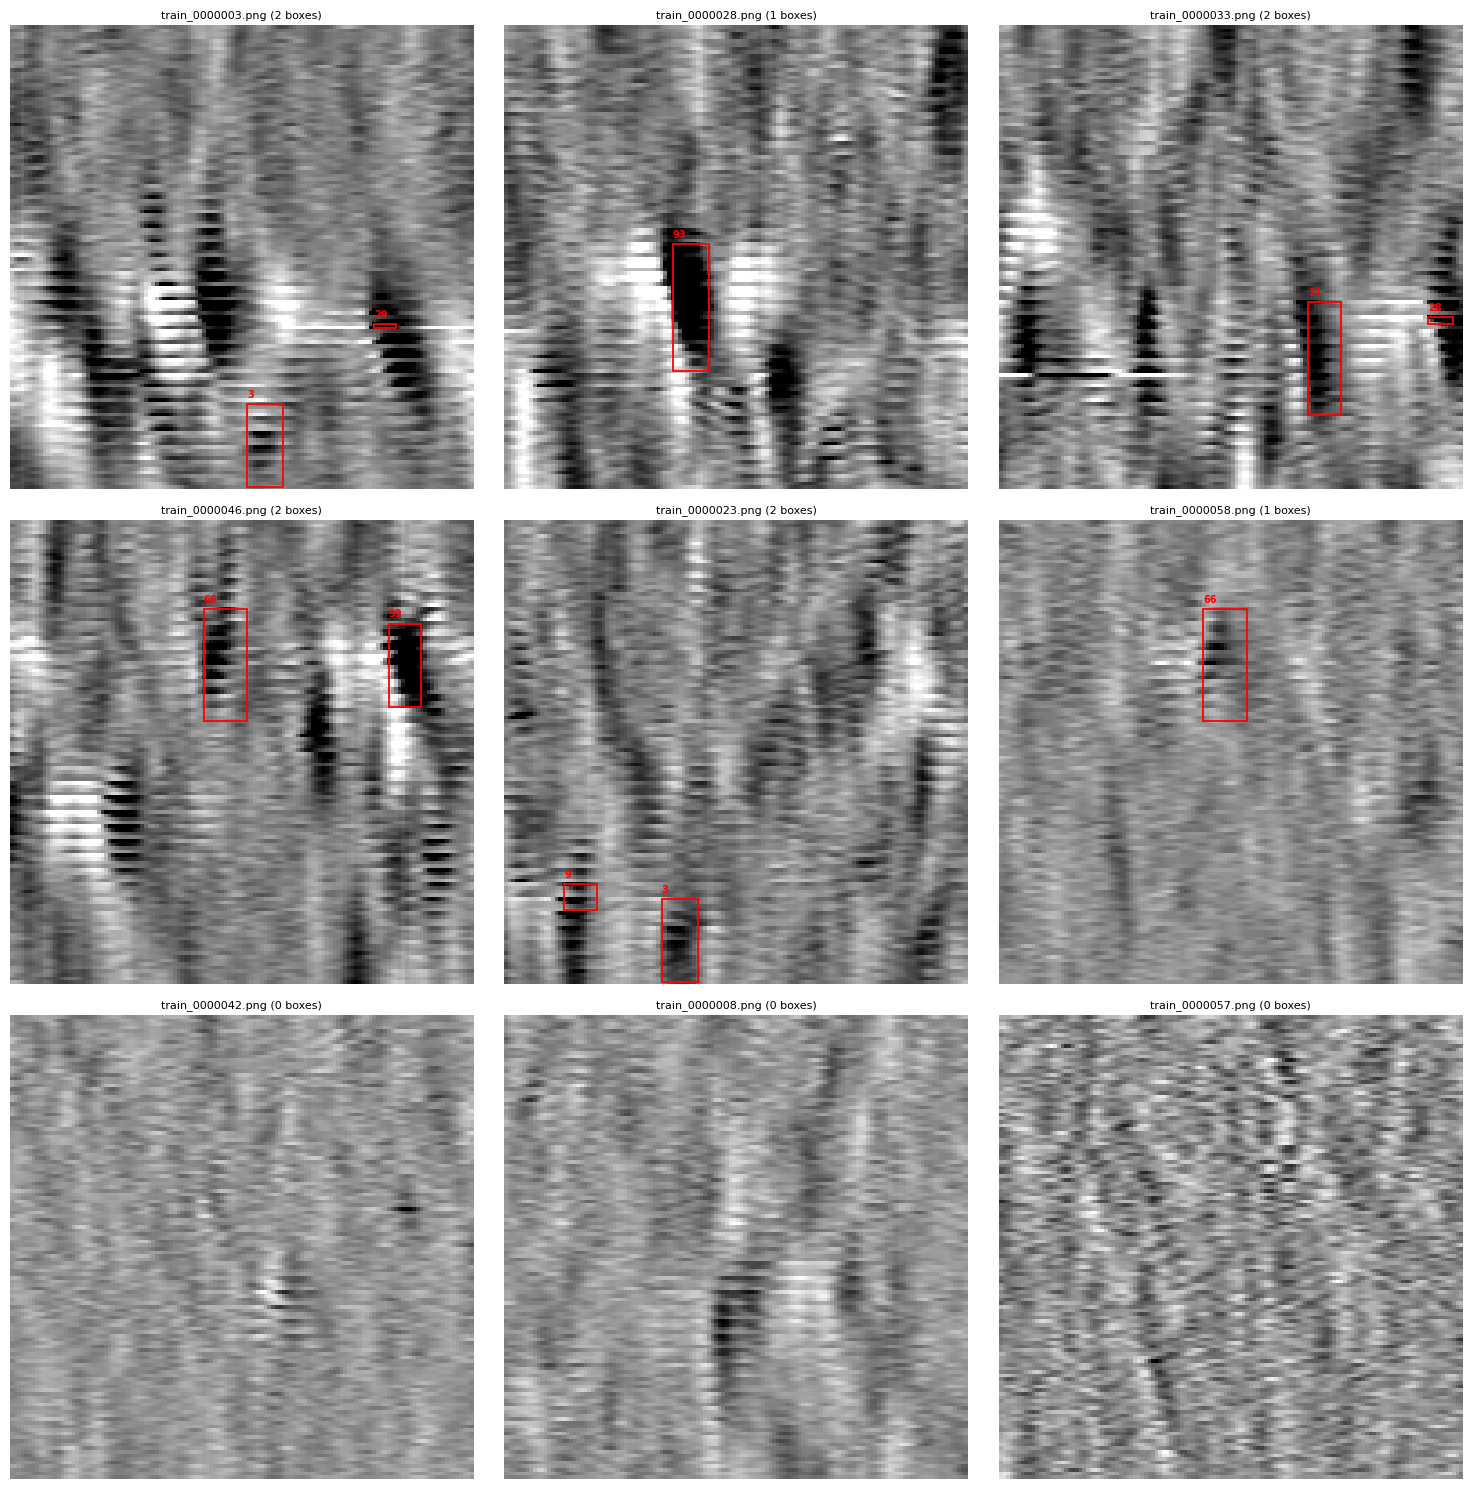

In [172]:
import glob
import random
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches

img_paths = glob.glob("dataset_overfit_test/images/train/*.png")
print(f"found {len(img_paths)} images")

sample_paths = random.sample(img_paths, min(9, len(img_paths)))

fig, axes = plt.subplots(3, 3, figsize=(15, 15))

for ax, img_path in zip(axes.flat, sample_paths):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    label_path = img_path.replace("images", "labels").replace(".png", ".txt")

    ax.imshow(img, cmap="gray")
    h, w = img.shape

    n_boxes = 0
    if os.path.exists(label_path):
        with open(label_path) as f:
            for line in f:
                parts = line.split()
                if len(parts) < 5:
                    continue
                cls, xc, yc, bw, bh = map(float, parts)
                x0 = (xc - bw / 2) * w
                y0 = (yc - bh / 2) * h
                rect = patches.Rectangle((x0, y0), bw * w, bh * h,
                                          linewidth=1.3, edgecolor='red', facecolor='none')
                ax.add_patch(rect)
                ax.text(x0, y0 - 2, str(int(cls)), color='red', fontsize=7, weight='bold')
                n_boxes += 1

    ax.set_title(f"{os.path.basename(img_path)} ({n_boxes} boxes)", fontsize=8)
    ax.axis('off')

plt.tight_layout()
plt.show()

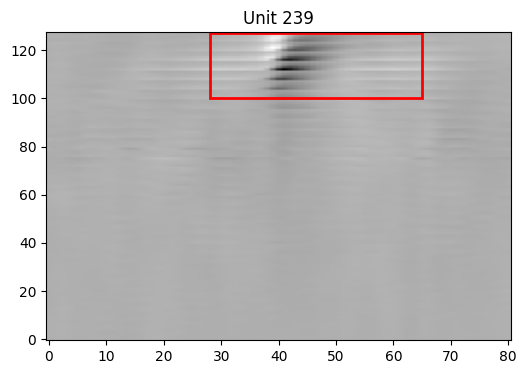

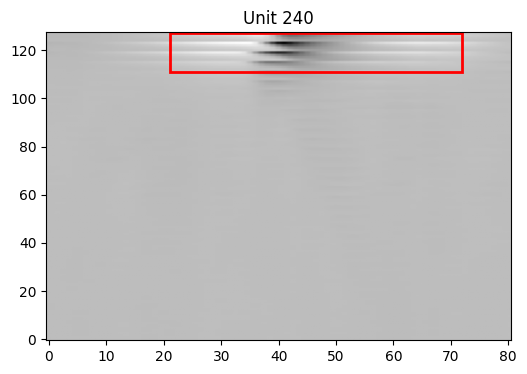

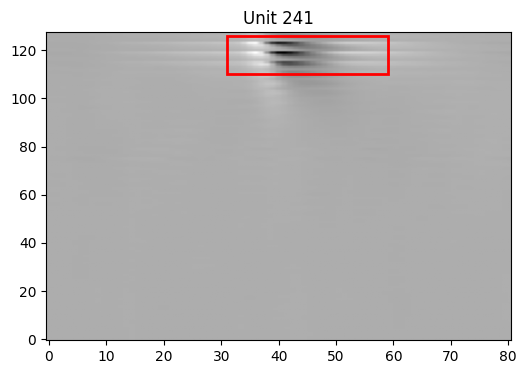

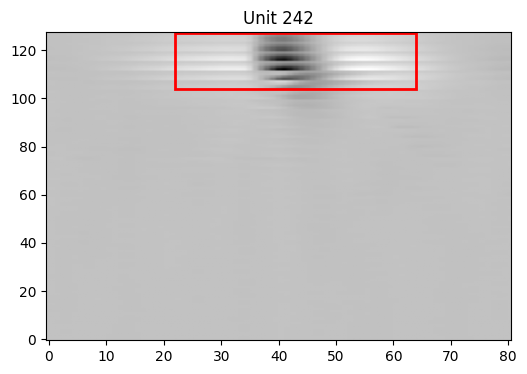

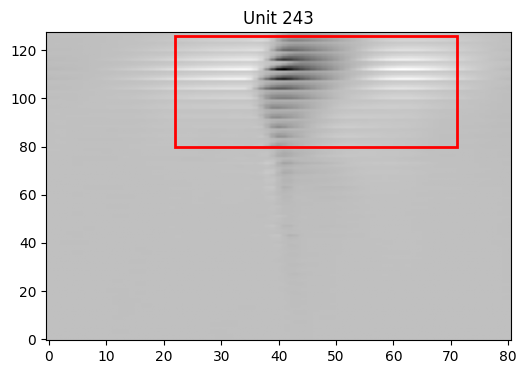

In [166]:
import matplotlib.pyplot as plt
import numpy as np

example_units = unit_ids[:5]

for unit_id in example_units:

    # 1. Extract raw waveform
    waveform_raw = sorting.get_property(
        "mean_waveform_all_channels_filt",
        [unit_id]
    )[0]
    
    # 2. Transform into geometric domain to match bounding box coordinates
    waveform_geo = waveform_raw[:, channel_order]

    box = box_lookup[unit_id] # Ensure this dictionary contains the geometrically calculated parameters

    plt.figure(figsize=(6,4))

    # 3. Plot the geometrically sorted matrix
    plt.imshow(
        waveform_geo.T,
        aspect="auto",
        origin="lower",
        cmap="gray"
    )

    # 4. Extract geometric peak and compute temporal alignment
    peak_ch = box["peak_channel"] 
    peak_time = np.argmax(np.abs(waveform_geo[:, peak_ch]))

    # 5. Compute temporal (X) and spatial (Y) dimensions
    x0 = peak_time - box["left"]
    box_width = box["left"] + box["right"]

    # Compute lower-left Y anchor (origin='lower' dictates Y increases upward)
    y0 = peak_ch - box["top"]
    box_height = box["top"] + box["bottom"]

    # 6. Render accurately bound patch
    plt.gca().add_patch(
        plt.Rectangle(
            (x0, y0),
            box_width,
            box_height,
            fill=False,
            color="red",
            linewidth=2
        )
    )

    plt.title(f"Unit {unit_id}")
    plt.show()
    

frame: 1317573
class: 16
channel: 34


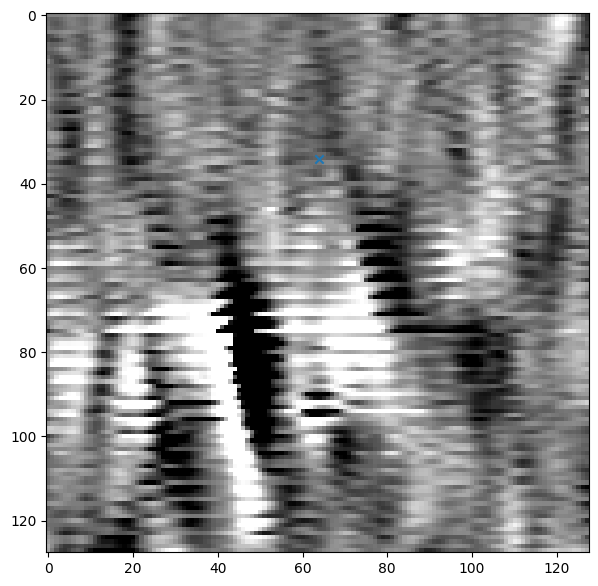

In [174]:
event = balanced_events[5000]

print("frame:", event[0])
print("class:", event[1])
print("channel:", event[2])


raw, norm = extract_window(
    event[0] - WINDOW_SIZE//2
)


plt.figure(figsize=(7,7))
plt.imshow(
    norm,
    aspect="auto",
    cmap="gray",
    vmin=-6,
    vmax=6
)

plt.scatter(
    WINDOW_SIZE//2,
    event[2],
    marker="x"
)

plt.show()

In [183]:
analyzer = si.create_sorting_analyzer(
    sorting=sorting,
    recording=recording,
    format="binary_folder",
    folder="sorting_analyzer"
)

/opt/anaconda3/envs/spike/lib/python3.11/site-packages/spikeinterface/core/baserecordingsnippets.py:259: UserWarning: There is no Probe attached to this recording. Creating a dummy one with contact positions
  warn("There is no Probe attached to this recording. Creating a dummy one with contact positions")


estimate_sparsity (no parallelization):   0%|          | 0/2393 [00:00<?, ?it/s]

/opt/anaconda3/envs/spike/lib/python3.11/site-packages/spikeinterface/core/baserecordingsnippets.py:259: UserWarning: There is no Probe attached to this recording. Creating a dummy one with contact positions
  warn("There is no Probe attached to this recording. Creating a dummy one with contact positions")


In [195]:
from pathlib import Path
ext_dir = Path("sorting_analyzer") / "extensions" / "templates"
print(ext_dir.exists())
if ext_dir.exists():
    print(list(ext_dir.iterdir()))
import shutil
from pathlib import Path

shutil.rmtree(Path("sorting_analyzer") / "extensions" / "templates", ignore_errors=True)

import spikeinterface as si
analyzer = si.load_sorting_analyzer("sorting_analyzer")
print(analyzer.get_loaded_extension_names())  # should show only ['random_spikes'] now

analyzer.compute("random_spikes")
analyzer.compute("templates")
analyzer.compute("waveforms")
analyzer.compute("noise_levels")
analyzer.compute("unit_locations")
analyzer.compute("correlograms")
analyzer.compute("spike_amplitudes")
analyzer.compute("template_similarity")
analyzer.compute("quality_metrics")


False
['random_spikes']


estimate_templates_with_accumulator (no parallelization):   0%|          | 0/2393 [00:00<?, ?it/s]

compute_waveforms (no parallelization):   0%|          | 0/2393 [00:00<?, ?it/s]

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

AssertionError: Extension unit_locations requires templates to be computed first

In [197]:
analyzer.compute("templates")
analyzer.compute("noise_levels")
analyzer.compute("unit_locations")
analyzer.compute("correlograms")
analyzer.compute("spike_amplitudes")

spike_amplitudes (no parallelization):   0%|          | 0/2393 [00:00<?, ?it/s]